# Capítulo 2. Ecuaciones de primer orden
## Sección 2.2.3. Dependencia respecto del dato inicial y jacobiano del flujo

**Fuente principal:** páginas 4–7 de `Ecuacione Lineales De Primer Orden.pdf`.

Esta sección estudia la dependencia

$$
X(t;x_0)
$$

respecto del punto inicial y el cambio local de volumen producido por el flujo.

### Ejemplo gráfico complementario · Separación de trayectorias

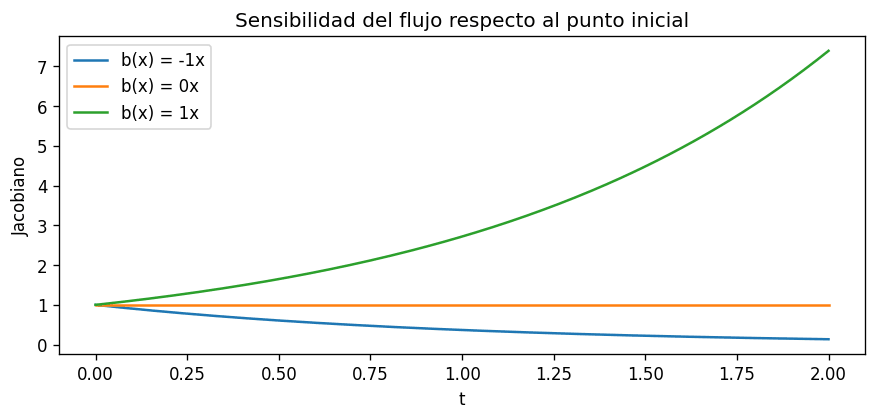

In [1]:
import numpy as np
import matplotlib.pyplot as plt

fig, ax = plt.subplots(figsize=(7.4,3.6))
t=np.linspace(0,2,180)
for tasa in [-1,0,1]:
    ax.plot(t,np.exp(tasa*t),label=f"b(x) = {tasa}x")
ax.set(xlabel="t",ylabel="Jacobiano",title="Sensibilidad del flujo respecto al punto inicial")
ax.legend()
fig.tight_layout()
plt.show()

# 2.2.3. Transcripción organizada de las notas

Las características se parametrizan por el dato inicial:

$$
X=X(t;x_0).
$$

En el método de características aparece una condición de no degeneración expresada mediante un determinante distinto de cero.

> **Aclaración.** Para un flujo en $\mathbb{R}^d$, la condición correspondiente es
> $$
> \det D_{x_0}X(t;x_0)\neq0.
> $$

# 2.2.4. Desarrollo formal

## Definición 2.2.13 — Matriz de deformación

Sea

$$
A(t;x_0)=D_{x_0}X(t;x_0).
$$

## Proposición 2.2.14 — Ecuación variacional

Si

$$
a\in C^1,
$$

entonces

$$
\begin{cases}
A'(t;x_0)
=
D_xa(X(t;x_0),t)A(t;x_0),\\
A(0;x_0)=I_d.
\end{cases}
$$

### Demostración

Se deriva respecto de $x_0$ la ecuación

$$
X'(t;x_0)=a(X(t;x_0),t)
$$

y se aplica la regla de la cadena.

## Definición 2.2.15 — Jacobiano del flujo

Se define

$$
J(t;x_0)
=
\det D_{x_0}X(t;x_0).
$$

## Teorema 2.2.16 — Fórmula de Liouville

El jacobiano satisface

$$
J'(t;x_0)
=
(\nabla\cdot a)(X(t;x_0),t)J(t;x_0),
$$

con

$$
J(0;x_0)=1.
$$

Por tanto,

$$
\boxed{
J(t;x_0)
=
\exp\left(
\int_0^t
(\nabla\cdot a)(X(s;x_0),s)\,ds
\right)
}.
$$

### Demostración

Por la fórmula de Jacobi,

$$
\frac{d}{dt}\det A
=
\det A\,
\operatorname{tr}(A^{-1}A').
$$

Como

$$
A'=D_xa\,A,
$$

la invariancia de la traza bajo semejanza produce

$$
\operatorname{tr}(A^{-1}D_xa\,A)
=
\operatorname{tr}(D_xa)
=
\nabla\cdot a.
$$

## Corolario 2.2.17 — Inversión local

Como

$$
J(t;x_0)>0,
$$

el teorema de la función inversa garantiza que el flujo es localmente invertible.

## Observación 2.2.18 — Preservación de volumen

Si

$$
\nabla\cdot a=0,
$$

entonces

$$
J(t;x_0)=1.
$$

# 2.2.5. Ejemplos

## Ejemplo 2.2.19 — Dilatación

Para

$$
a(x)=\lambda x,
$$

se tiene

$$
X(t;x_0)=e^{\lambda t}x_0
$$

y

$$
J(t;x_0)=e^{d\lambda t}.
$$

## Ejemplo 2.2.20 — Rotación plana

Para

$$
a(x,y)=(-y,x),
$$

se tiene

$$
\nabla\cdot a=0
$$

y

$$
J(t)=1.
$$

## Resultado añadido 2.2.21 — Cambio de variables

Si el flujo es inyectivo sobre $E$,

$$
\int_{\Phi_t(E)}h(x)\,dx
=
\int_E
h(X(t;x_0))J(t;x_0)\,dx_0.
$$

# 2.2.6. Visualización Manim

Se comparan:

$$
a_1(x,y)=(x,y),
$$

con

$$
J_1(t)=e^{2t},
$$

y

$$
a_2(x,y)=(-y,x),
$$

con

$$
J_2(t)=1.
$$

Los dominios iniciales permanecen visibles durante cuatro segundos.

In [ ]:
import os
import shutil
import tempfile
import uuid
from pathlib import Path

def miktex_candidates():
    candidates = []
    for base in (
        os.environ.get("LOCALAPPDATA"),
        os.environ.get("ProgramFiles"),
        os.environ.get("ProgramFiles(x86)"),
    ):
        if not base:
            continue
        root = Path(base)
        candidates.extend([
            root / "Programs" / "MiKTeX" / "miktex" / "bin" / "x64",
            root / "Programs" / "MiKTeX" / "miktex" / "bin",
            root / "MiKTeX" / "miktex" / "bin" / "x64",
            root / "MiKTeX" / "miktex" / "bin",
        ])
    return candidates

for candidate in miktex_candidates():
    if candidate.exists():
        os.environ["PATH"] = (
            str(candidate)
            + os.pathsep
            + os.environ.get("PATH", "")
        )

latex_exe = shutil.which("latex")
dvisvgm_exe = shutil.which("dvisvgm")

if latex_exe is None or dvisvgm_exe is None:
    raise RuntimeError(
        "No se encontraron latex.exe y dvisvgm.exe. "
        "Abre MiKTeX Console, completa la instalación y reinicia el kernel."
    )

from manim import config, __version__ as manim_version

TEX_RUNTIME_DIR = (
    Path(tempfile.gettempdir())
    / f"manim_tex_recuperado_{os.getpid()}_{uuid.uuid4().hex[:10]}"
)
TEX_RUNTIME_DIR.mkdir(parents=True, exist_ok=True)

config.no_latex_cleanup = True
config.tex_dir = str(TEX_RUNTIME_DIR)
config.media_embed = True
config.media_width = "100%"

print(f"Manim Community: {manim_version}")
print("latex   :", latex_exe)
print("dvisvgm :", dvisvgm_exe)
print("TeX dir :", TEX_RUNTIME_DIR)
print("Render preparado: 2560×1440, 120 fps")
print("La animación no ha sido compilada.")

In [ ]:
%%manim -v WARNING -r 2560,1440 --fps 120 JacobianoDelFlujo

from manim import *
import numpy as np

config.no_latex_cleanup = True
config.tex_dir = str(TEX_RUNTIME_DIR)
config.media_embed = True
config.media_width = "100%"


class JacobianoDelFlujo(Scene):
    def construct(self):
        self.camera.background_color = "#0B1020"

        title = Text(
            "Dependencia inicial y jacobiano del flujo",
            font_size=40,
            weight=BOLD,
        ).to_edge(UP, buff=0.20)

        formula = MathTex(
            r"J(t;x_0)=\exp\left(\int_0^t(\nabla\cdot a)(X(s),s)\,ds\right)",
            font_size=34,
            color=YELLOW_C,
        ).next_to(title, DOWN, buff=0.12)

        left_axes = Axes(
            x_range=[-3, 3, 1],
            y_range=[-3, 3, 1],
            x_length=5.4,
            y_length=5.4,
            tips=False,
        ).shift(3.5 * LEFT + 0.55 * DOWN)

        right_axes = Axes(
            x_range=[-3, 3, 1],
            y_range=[-3, 3, 1],
            x_length=5.4,
            y_length=5.4,
            tips=False,
        ).shift(3.5 * RIGHT + 0.55 * DOWN)

        left_title = MathTex(
            r"a_1(x,y)=(x,y)",
            font_size=31,
            color=ORANGE,
        ).next_to(left_axes, UP, buff=0.10)

        right_title = MathTex(
            r"a_2(x,y)=(-y,x)",
            font_size=31,
            color=TEAL_C,
        ).next_to(right_axes, UP, buff=0.10)

        tracker = ValueTracker(0.0)

        expanding_square = always_redraw(
            lambda: Polygon(
                *[
                    left_axes.c2p(
                        np.exp(tracker.get_value()) * x,
                        np.exp(tracker.get_value()) * y,
                    )
                    for x, y in [
                        (-0.7, -0.7),
                        (0.7, -0.7),
                        (0.7, 0.7),
                        (-0.7, 0.7),
                    ]
                ],
                color=ORANGE,
                fill_color=ORANGE,
                fill_opacity=0.22,
                stroke_width=5,
            )
        )

        rotating_square = always_redraw(
            lambda: Polygon(
                *[
                    right_axes.c2p(
                        np.cos(tracker.get_value()) * x
                        - np.sin(tracker.get_value()) * y,
                        np.sin(tracker.get_value()) * x
                        + np.cos(tracker.get_value()) * y,
                    )
                    for x, y in [
                        (-0.7, -0.7),
                        (0.7, -0.7),
                        (0.7, 0.7),
                        (-0.7, 0.7),
                    ]
                ],
                color=TEAL_C,
                fill_color=TEAL_C,
                fill_opacity=0.22,
                stroke_width=5,
            )
        )

        t_number = DecimalNumber(
            0.0,
            num_decimal_places=2,
            font_size=29,
            color=GREEN_C,
        )
        t_number.add_updater(
            lambda mob: mob.set_value(tracker.get_value())
        )

        j1_number = DecimalNumber(
            1.0,
            num_decimal_places=3,
            font_size=28,
            color=ORANGE,
        )
        j1_number.add_updater(
            lambda mob: mob.set_value(np.exp(2 * tracker.get_value()))
        )

        display = VGroup(
            VGroup(
                MathTex(r"t=", font_size=29),
                t_number,
            ).arrange(RIGHT, buff=0.05),
            VGroup(
                MathTex(r"J_1=", font_size=28, color=ORANGE),
                j1_number,
            ).arrange(RIGHT, buff=0.05),
            MathTex(r"J_2=1", font_size=28, color=TEAL_C),
        ).arrange(DOWN, buff=0.12).to_edge(DOWN, buff=0.20)

        self.play(
            FadeIn(title),
            Write(formula),
            Create(left_axes),
            Create(right_axes),
            FadeIn(left_title),
            FadeIn(right_title),
            FadeIn(expanding_square),
            FadeIn(rotating_square),
            FadeIn(display),
            run_time=3.0,
        )

        self.wait(4.0)

        self.play(
            tracker.animate.set_value(1.0),
            run_time=11.0,
            rate_func=linear,
        )

        self.wait(3.0)

        t_number.clear_updaters()
        j1_number.clear_updaters()

# 2.2.7. Ejercicios propuestos

1. Calcule el jacobiano del flujo de
   $$
   a(x,y)=(2x,-y).
   $$

2. Demuestre que un campo con divergencia cero preserva áreas en $\mathbb{R}^2$.

3. Para
   $$
   a(x,y,t)=(x+t,-2y),
   $$
   obtenga el flujo, la matriz de deformación y el jacobiano.

4. Justifique cuidadosamente el cambio de variables inducido por un flujo localmente invertible.

# Revisión

Se recuperaron la ecuación variacional, la fórmula de Liouville, la interpretación volumétrica y la inversión local del flujo.

La siguiente sección lógica es el sistema característico de una ecuación cuasilineal.